In [64]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [65]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt


In [66]:
online_deliveries=pd.read_csv('/content/drive/MyDrive/Machine learning files/datasets/online food delivery dataset.csv')
online_deliveries.head()

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,Yes


In [67]:
online_deliveries.dropna(inplace=True)

In [68]:
online_deliveries['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [69]:
online_deliveries['Gender']=online_deliveries['Gender'].map({'Female':1,'Male':0})

In [70]:
online_deliveries['Output']=online_deliveries['Output'].map({'Yes':1,'No':0})

In [71]:
online_deliveries['Feedback'].unique()

array(['Positive', 'Negative '], dtype=object)

In [72]:
online_deliveries['Feedback']=online_deliveries['Feedback'].map({'Positive':1,'Negative ':0})


In [73]:
online_deliveries['Unnamed: 13']=online_deliveries['Unnamed: 13'].map({'Yes':1,'No':0})

In [74]:
online_deliveries

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,1,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,1,1,1
1,24,1,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,1,1,1
2,22,0,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,1,0,1
3,22,1,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,1,1,1
4,22,0,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
383,23,1,Single,Student,No Income,Post Graduate,2,Regular,12.9766,77.5993,560001,1,1,1
384,23,1,Single,Student,No Income,Post Graduate,4,Frequent,12.9854,77.7081,560048,1,1,1
385,22,1,Single,Student,No Income,Post Graduate,5,Frequent,12.9850,77.5533,560010,1,1,1
386,23,0,Single,Student,Below Rs.10000,Post Graduate,2,Regular,12.9770,77.5773,560009,1,1,1


In [75]:
online_deliveries=pd.get_dummies(online_deliveries,columns=['Occupation','Marital Status','Monthly Income','Educational Qualifications','Customer Type'])

In [76]:

online_deliveries.head()

,Age,Gender,Family size,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13,Occupation_Employee,...,Monthly Income_More than 50000,Monthly Income_No Income,Educational Qualifications_Graduate,Educational Qualifications_Ph.D,Educational Qualifications_Post Graduate,Educational Qualifications_School,Educational Qualifications_Uneducated,Customer Type_Frequent,Customer Type_New,Customer Type_Regular
0,20,1,4,12.9766,77.5993,560001,1,1,1,False,...,False,True,False,False,True,False,False,True,False,False
1,24,1,3,12.9770,77.5773,560009,1,1,1,False,...,False,False,True,False,False,False,False,False,False,True
2,22,0,3,12.9551,77.6593,560017,1,0,1,False,...,False,False,False,False,True,False,False,False,False,True
3,22,1,6,12.9473,77.5616,560019,1,1,1,False,...,False,True,True,False,False,False,False,True,False,False
4,22,0,4,12.9850,77.5533,560010,1,1,1,False,...,False,False,False,False,True,False,False,True,False,False


In [77]:
for index, col_name in enumerate(online_deliveries.columns):
  print(f"Index {index}: {col_name}")

Index 0: Age
Index 1: Gender
Index 2: Family size
Index 3: latitude
Index 4: longitude
Index 5: Pin code
Index 6: Output
Index 7: Feedback
Index 8: Unnamed: 13
Index 9: Occupation_Employee
Index 10: Occupation_House wife
Index 11: Occupation_Self Employeed
Index 12: Occupation_Student
Index 13: Marital Status_Married
Index 14: Marital Status_Prefer not to say
Index 15: Marital Status_Single
Index 16: Monthly Income_10001 to 25000
Index 17: Monthly Income_25001 to 50000
Index 18: Monthly Income_Below Rs.10000
Index 19: Monthly Income_More than 50000
Index 20: Monthly Income_No Income
Index 21: Educational Qualifications_Graduate
Index 22: Educational Qualifications_Ph.D
Index 23: Educational Qualifications_Post Graduate
Index 24: Educational Qualifications_School
Index 25: Educational Qualifications_Uneducated
Index 26: Customer Type_Frequent
Index 27: Customer Type_New
Index 28: Customer Type_Regular


In [78]:
y=online_deliveries.iloc[:,26]


In [79]:
online_deliveries=online_deliveries.drop('Customer Type_Frequent',axis=1)

In [80]:
x=online_deliveries.iloc[:,0:]
x

,Age,Gender,Family size,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13,Occupation_Employee,...,Monthly Income_Below Rs.10000,Monthly Income_More than 50000,Monthly Income_No Income,Educational Qualifications_Graduate,Educational Qualifications_Ph.D,Educational Qualifications_Post Graduate,Educational Qualifications_School,Educational Qualifications_Uneducated,Customer Type_New,Customer Type_Regular
0,20,1,4,12.9766,77.5993,560001,1,1,1,False,...,False,False,True,False,False,True,False,False,False,False
1,24,1,3,12.9770,77.5773,560009,1,1,1,False,...,True,False,False,True,False,False,False,False,False,True
2,22,0,3,12.9551,77.6593,560017,1,0,1,False,...,True,False,False,False,False,True,False,False,False,True
3,22,1,6,12.9473,77.5616,560019,1,1,1,False,...,False,False,True,True,False,False,False,False,False,False
4,22,0,4,12.9850,77.5533,560010,1,1,1,False,...,True,False,False,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
383,23,1,2,12.9766,77.5993,560001,1,1,1,False,...,False,False,True,False,False,True,False,False,False,True
384,23,1,4,12.9854,77.7081,560048,1,1,1,False,...,False,False,True,False,False,True,False,False,False,False
385,22,1,5,12.9850,77.5533,560010,1,1,1,False,...,False,False,True,False,False,True,False,False,False,False
386,23,0,2,12.9770,77.5773,560009,1,1,1,False,...,True,False,False,False,False,True,False,False,False,True


data visualisation

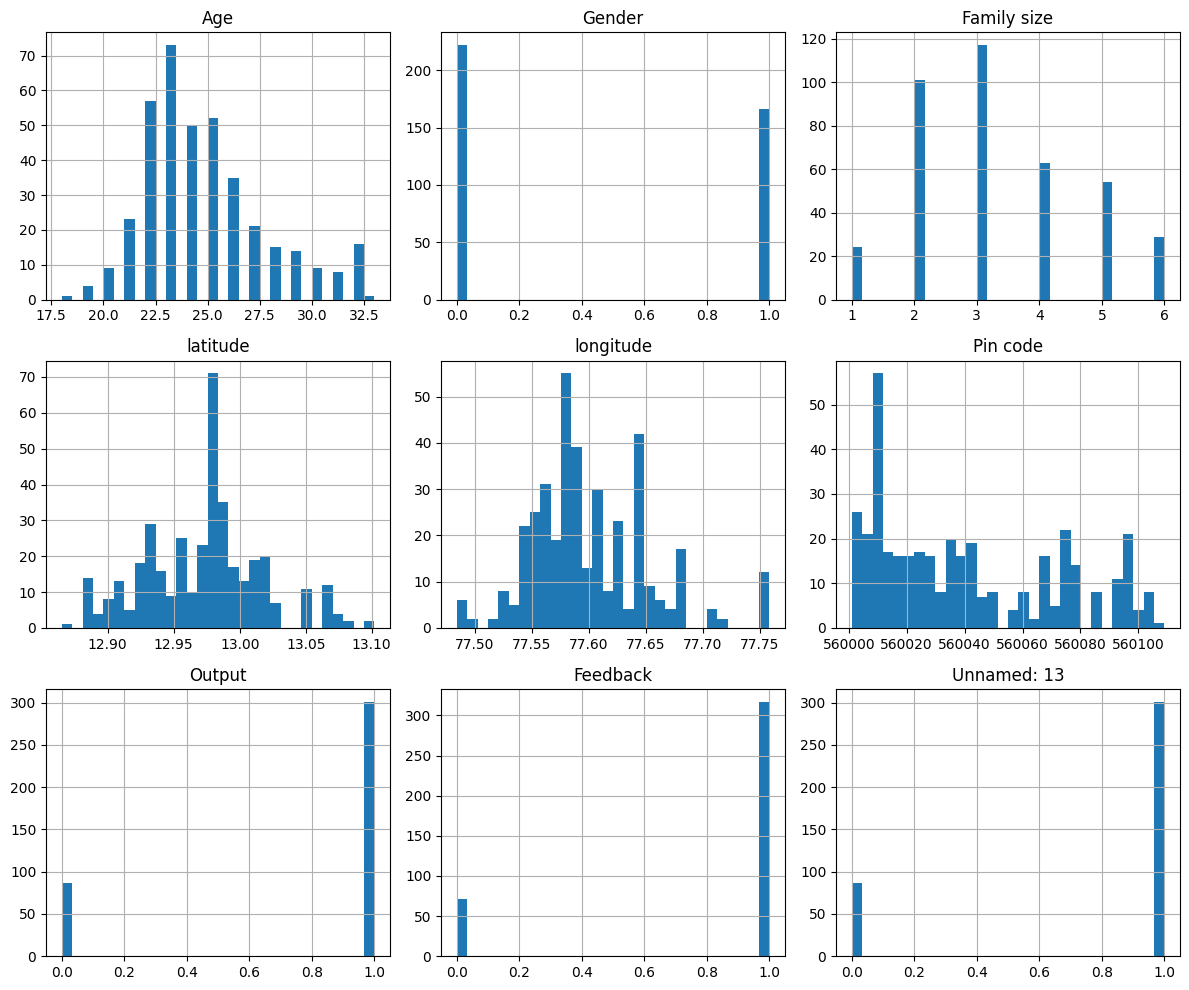

In [81]:
x.hist(bins=30,figsize=(12,10))
plt.tight_layout()
plt.show()

DATA SPLIT

In [82]:
x_train,x_temp,y_train,y_temp=train_test_split(x,y,test_size=0.2)
x_dev,x_test,y_dev,y_test=train_test_split(x_temp,y_temp,test_size=0.5)

DATA VISUALISATION

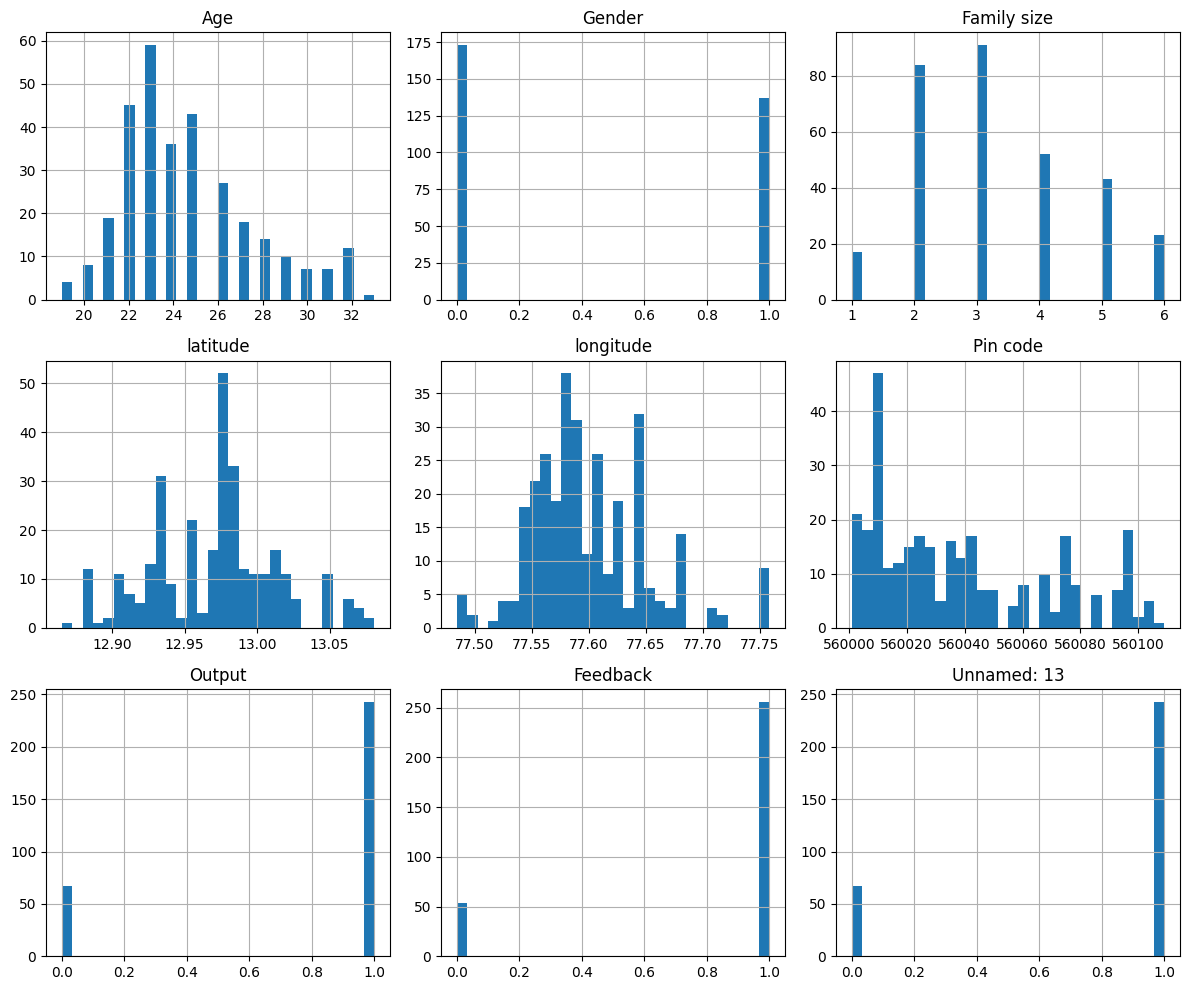

In [83]:
x_train.hist(bins=30,figsize=(12,10))
plt.tight_layout()
plt.show()

DATA SCALLING

In [84]:
scaler1=StandardScaler()
x_train_scaled=scaler1.fit_transform(x_train)
x_dev_scaled=scaler1.transform(x_dev)
x_test_scaled=scaler1.transform(x_test)


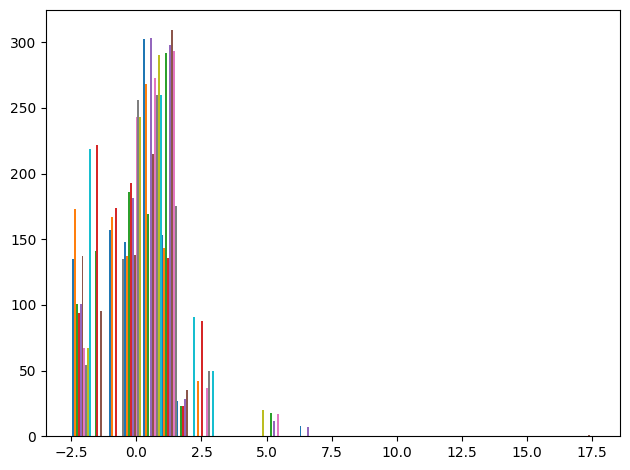

In [85]:
plt.hist(x_train_scaled,bins=10,rwidth=500)
plt.tight_layout()
plt.show()

In [86]:
y_train.unique()

array([ True, False])

converting data into tensors

In [87]:
x_train_tensor=torch.tensor(x_train_scaled,dtype=torch.float32)
x_test_tensor=torch.tensor(x_test_scaled,dtype=torch.float32)
x_dev_tensor=torch.tensor(x_dev_scaled,dtype=torch.float32)

In [88]:
y_train_tensor=torch.tensor(y_train.values,dtype=torch.float32)
y_dev_tensor=torch.tensor(y_dev.values,dtype=torch.float32)
y_test_tensor=torch.tensor(y_test.values,dtype=torch.float32)

In [89]:
features_x=x_train_tensor.shape[1]

In [90]:
y_train_tensor=y_train_tensor.unsqueeze(1)
y_test_tensor=y_test_tensor.unsqueeze(1)
y_dev_tensor=y_dev_tensor.unsqueeze(1)

In [135]:



#nn achitecture
class neuralnetwork(nn.Module):
  def __init__(self,features):
    super().__init__()
    self.layer1=nn.Linear(features,60)
    self.layer2=nn.Linear(60,30)
    self.output_n=nn.Linear(30,1)
    self.relu=nn.ReLU()
  def forward(self,x):
    z1=self.layer1(x)
    a1=self.relu(z1)

    z2=self.layer2(a1)
    a2=self.relu(z2)

    z3=self.output_n(a2)
    a3=z3 #linear activation

    return a3

torch.manual_seed(42)
model=neuralnetwork(features_x)
#loss function
loss=nn.BCEWithLogitsLoss()
#optimizer
optimizer=torch.optim.SGD(model.parameters(),lr=0.01)










In [136]:
# training loop
for epoch in range(500):

    optimizer.zero_grad()

    # forward pass
    prediction = model(x_train_tensor)

    # loss
    loss_value = loss(prediction, y_train_tensor)

    # backpropagation + gradients
    loss_value.backward()

    # update parameters
    optimizer.step()

    if epoch % 50 == 0:
        print(f'epoch:{epoch}, loss:{loss_value.item():.2f}')

epoch:0, loss:0.70
epoch:50, loss:0.68
epoch:100, loss:0.65
epoch:150, loss:0.63
epoch:200, loss:0.60
epoch:250, loss:0.57
epoch:300, loss:0.52
epoch:350, loss:0.47
epoch:400, loss:0.41
epoch:450, loss:0.34


In [141]:
# =========================
# DEV / VALIDATION SET
# =========================

model.eval()

with torch.no_grad():

    dev_logits = model(x_dev_tensor)

    dev_probabilities = torch.sigmoid(dev_logits)

    dev_predictions = (dev_probabilities >= 0.5).float()

    dev_accuracy = (dev_predictions == y_dev_tensor ).float().mean()

    print(f"Dev accuracy: {dev_accuracy.item():.2f}")

Dev accuracy: 1.00


In [144]:
#DEV LOSS

model.eval()

with torch.no_grad():
  dev_prediction=model(x_dev_tensor)
  dev_loss=loss(dev_prediction,y_dev_tensor)

  print(f'dev_loss:{dev_loss.item():.2f}')



dev_loss:0.27


In [146]:
# =========================
# TEST SET
# =========================

model.eval()

with torch.no_grad():

    test_logits = model(x_test_tensor)

    test_probabilities = torch.sigmoid(test_logits)

    test_predictions = (test_probabilities >= 0.5).float()

    test_accuracy = (test_predictions == y_test_tensor).float().mean()

    print(f"Test accuracy: {test_accuracy.item():.2f}")

Test accuracy: 0.97


In [148]:
#TEST LOSS
model.eval()

with torch.no_grad():
  test_prediction=model(x_test_tensor)
  test_loss=loss(test_prediction,y_test_tensor)
  print(f'test_loss:{test_loss.item():.2f}')

test_loss:0.31


In [97]:
# =========================
# SAVE MODEL
# =========================

torch.save(
    model.state_dict(),
    "neural_network.pth"
)